# scATAC UMAP legend (standalone)

Generates a separate legend panel for the scATAC UMAP (Figure 3c). Colors match `CATEGORY_COLORS` in `scatac_celltype_classification.ipynb`. Reads the UMAP coordinates written by that notebook (`../output/scatac_umap_coords.csv`) and writes the legend to `../output/`.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from this notebook's folder (nbconvert default),
# from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA)
print("OUT :", OUT)

DATA: /home/jingz/leaf-1-figures/scatac/data
OUT : /home/jingz/leaf-1-figures/scatac/output


saved: /home/jingz/leaf-1-figures/scatac/output/scatac_umap_legend.pdf
saved: /home/jingz/leaf-1-figures/scatac/output/scatac_umap_legend.png
saved: /home/jingz/leaf-1-figures/scatac/output/scatac_umap_legend.svg
saved: /home/jingz/leaf-1-figures/scatac/output/scatac_umap_legend.tsv


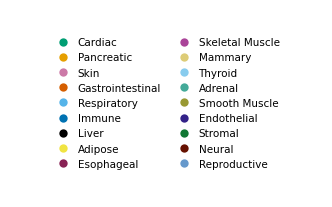

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Liberation Sans', 'Arial', 'Helvetica'],
    'font.size': 6,
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 5,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'figure.dpi': 150,
    'savefig.dpi': 600,
    'pdf.fonttype': 42,
})

# Same color mapping as the UMAP cell in scatac_celltype_classification.ipynb.
CATEGORY_COLORS = {
    'Cardiac': '#009E73', 'Pancreatic': '#E69F00', 'Skin': '#CC79A7',
    'Gastrointestinal': '#D55E00', 'Respiratory': '#56B4E9', 'Immune': '#0072B2',
    'Liver': '#000000', 'Adipose': '#F0E442', 'Esophageal': '#882255',
    'Skeletal Muscle': '#AA4499', 'Mammary': '#DDCC77', 'Thyroid': '#88CCEE',
    'Adrenal': '#44AA99', 'Smooth Muscle': '#999933', 'Endothelial': '#332288',
    'Stromal': '#117733', 'Neural': '#661100', 'Reproductive': '#6699CC',
}

# Use exactly the categories present in the UMAP, in the canonical color order.
coords = pd.read_csv(OUT / 'scatac_umap_coords.csv')
present = [c for c in CATEGORY_COLORS if (coords['category'] == c).any()]

handles = [Line2D([0], [0], marker='o', linestyle='none', markersize=4,
                  markerfacecolor=CATEGORY_COLORS[c], markeredgecolor='none', label=c)
           for c in present]

ncol = 2
nrow = int(np.ceil(len(present) / ncol))
fig, ax = plt.subplots(figsize=(2.6, 0.16 * nrow + 0.1))
ax.axis('off')
ax.legend(handles=handles, loc='center', ncol=ncol, frameon=False,
          handletextpad=0.4, columnspacing=1.2, labelspacing=0.5,
          borderaxespad=0, fontsize=5)
savefig(fig, OUT, 'scatac_umap_legend',
        data=pd.DataFrame({'category': present, 'color': [CATEGORY_COLORS[c] for c in present]}))